# Projeto e relatório de um fatorial $2^2r$

## Do plano de coleta à conclusão

Este notebook reúne o percurso completo de um projeto com dois fatores, dois níveis por fator e replicações independentes. Ele funciona sozinho e contém um exemplo resolvido de desempenho de uma API. Os números são sintéticos e não descrevem o desempenho de um produto real.

O objetivo é produzir uma conclusão que possa ser examinada por outra pessoa. Para isso, a origem dos dados, as contas, as hipóteses e as decisões precisam estar registradas. Uma saída numérica deve sempre ser acompanhada da pergunta que ela responde.

Execute as células de cima para baixo. Primeiro acompanhe o exemplo. Depois substitua o contexto, os níveis, as respostas e os registros de execução pelos do seu projeto. A estrutura estatística pressupõe um fatorial completo balanceado com replicações independentes.


## Roteiro do trabalho

| Etapa | Produto esperado |
| --- | --- |
| Pergunta e planejamento | Uma decisão e uma diferença relevante definidas previamente |
| Organização dos dados | Quatro combinações identificadas e suas replicações |
| Modelo e efeitos | Estimativas de $q_0$, $q_A$, $q_B$ e $q_{AB}$ |
| Inferência | Hipóteses, testes e intervalos interpretados |
| Diagnóstico | Evidências sobre erros e limitações do modelo |
| Confirmação | Novas execuções para examinar a configuração escolhida |
| Relatório | Conclusão, incerteza e condições de aplicação |

As técnicas são desenvolvidas com mais detalhes nas partes anteriores da coleção. Aqui cada uma será retomada junto da decisão que ajuda a tomar.


## Preparação

Adotaremos intervalos de 90% para manter a convenção do exemplo da aula. Isso corresponde a $\alpha=0{,}10$ nos testes bilaterais associados. O nível deve ser definido no planejamento. Alterá-lo depois de observar o valor-p modifica a regra de decisão após conhecer os dados.

As funções auxiliares abaixo cuidam da apresentação e do salvamento. Os cálculos do experimento permanecerão nas células seguintes. As figuras terão fundo branco, tipografia serifada, ausência de título interno e dimensões físicas preservadas no PDF.


In [1]:
from pathlib import Path
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from IPython.display import display, Markdown

CONFIDENCE_LEVEL = 0.90
ALPHA = 1 - CONFIDENCE_LEVEL
NOME_NOTEBOOK = "07_projeto_e_relatorio_22r"
BASE = Path.cwd()
if BASE.name == "notebooks":
    BASE = BASE.parent
FIGURAS = BASE / "figuras" / NOME_NOTEBOOK
TABELAS = BASE / "tabelas" / NOME_NOTEBOOK
DADOS = BASE / "dados"
for pasta in [FIGURAS, TABELAS, DADOS]:
    pasta.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 10.5,
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9,
    "figure.figsize": (4, 3),
    "figure.dpi": 120,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.4,
    "lines.markersize": 4.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})
AZUL = "#24577A"
LARANJA = "#B76532"
VERDE = "#44735B"
CINZA = "#737373"
CORES = [AZUL, LARANJA, VERDE, CINZA]
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 110)
pd.set_option("display.float_format", lambda x: f"{x:.4g}")

def salvar_figura(fig, nome):
    for ax in fig.axes:
        if ax.get_title() or ax.get_title(loc="left") or ax.get_title(loc="right"):
            raise ValueError("A identificação da figura deve ficar no texto")
    if getattr(fig, "_suptitle", None) is not None:
        raise ValueError("A identificação da figura deve ficar no texto")
    dimensao = tuple(np.round(fig.get_size_inches(), 6))
    if dimensao not in [(4.0, 3.0), (5.0, 3.0)]:
        raise ValueError("Use dimensões de 4 por 3 ou 5 por 3 polegadas")
    pdf = FIGURAS / f"{nome}.pdf"
    png = FIGURAS / f"{nome}.png"
    fig.savefig(pdf, format="pdf", dpi=600)
    fig.savefig(png, format="png", dpi=180)
    imagem = base64.b64encode(png.read_bytes()).decode("ascii")
    display({"image/png": imagem}, raw=True,
            metadata={"fatorial_pdf": str(pdf.relative_to(BASE)),
                      "largura_polegadas": dimensao[0],
                      "altura_polegadas": dimensao[1]})
    plt.close(fig)

def salvar_tabela(tabela, nome, indice=False, colunas_p=None):
    tabela.to_csv(TABELAS / f"{nome}.csv", index=indice)
    apresentacao = tabela.copy()
    if colunas_p is not None:
        for coluna in colunas_p:
            apresentacao[coluna] = apresentacao[coluna].map(
                lambda valor: "" if pd.isna(valor) else (
                    f"{valor:.4g}" if valor > 0 else "abaixo da precisão numérica"))
    display(apresentacao)


## 1 Pergunta experimental

Uma equipe deseja reduzir a latência média de uma API sob uma carga de requisições definida. O fator $A$ é a quantidade de workers. O fator $B$ é o uso de cache. O mesmo servidor, a versão do serviço, o perfil da carga e a duração da janela de medição são mantidos durante o estudo.

Uma unidade experimental é uma sessão de benchmark. Antes de cada sessão, o estado é reinicializado e um período de aquecimento padronizado é cumprido. A resposta é a latência média em milissegundos calculada na janela de medição dessa sessão.

As requisições dentro de uma sessão são subamostras. Elas ajudam a calcular a resposta daquela sessão, mas não aumentam o número de replicações independentes do fatorial. O alcance da inferência permanece ligado ao ambiente e ao protocolo descritos.


In [2]:
fatores = pd.DataFrame({
    "Fator": ["A", "B"],
    "Significado": ["Quantidade de workers", "Cache"],
    "Nível -1": ["2", "Desativado"],
    "Nível +1": ["8", "Ativado"]
})
salvar_tabela(fatores, "fatores_e_niveis")

LIMITE_MEDIA = 75.0
LIMITE_SESSAO = 80.0
GANHO_RELEVANTE = 5.0


,Fator,Significado,Nível -1,Nível +1
0,A,Quantidade de workers,2,8
1,B,Cache,Desativado,Ativado


### Critérios definidos antes da análise

Neste exemplo, uma latência média de até 75 ms atende ao objetivo para a média do processo. Uma nova sessão tem um limite operacional de 80 ms. Uma redução de 5 ms em relação à configuração inicial já é considerada relevante.

Esses critérios se referem a objetos diferentes. Uma média populacional abaixo do limite não garante que toda sessão individual fique abaixo dele. Mais adiante calcularemos intervalos separados para a média e para uma nova sessão.

### Sua vez

Escreva a decisão do seu projeto, a unidade experimental, a unidade de medida da resposta e a diferença que teria importância prática. Identifique o que precisa ser reinicializado ou controlado para que uma nova replicação não seja apenas uma continuação da anterior.


## 2 Respostas em um array NumPy

Cada linha de `response` corresponde a uma combinação. A ordem é $A-B-$, $A+B-$, $A-B+$ e $A+B+$. Cada coluna contém uma replicação dessa combinação. A posição na coluna não cria pareamento entre linhas e não representa um bloco.

O formato $(4,r)$ indica quatro combinações e $r$ replicações em cada uma. O total de respostas é $N=4r$. Neste exemplo, as 24 respostas já estão escritas no código para que seja possível inspecionar os dados antes de qualquer cálculo.


In [3]:
response = np.array([
    [123.4, 117.8, 120.6, 126.1, 116.5, 121.7],
    [95.6, 100.4, 91.8, 97.2, 94.5, 99.1],
    [79.2, 74.8, 82.1, 77.4, 80.3, 75.9],
    [68.1, 71.4, 64.7, 69.5, 66.8, 72.0]
], dtype=float)


In [4]:
if response.ndim != 2 or response.shape[0] != 4:
    raise ValueError("O array precisa ter quatro linhas")
if response.shape[1] < 2:
    raise ValueError("São necessárias replicações para estimar o erro experimental")
if not np.isfinite(response).all():
    raise ValueError("Investigue valores ausentes ou não finitos antes da análise")

replications = response.shape[1]
N = response.size
A = np.array([-1, 1, -1, 1])
B = np.array([-1, -1, 1, 1])
AB = A * B
rotulos = ["A- B-", "A+ B-", "A- B+", "A+ B+"]
tabela_respostas = pd.DataFrame(response, index=rotulos,
                               columns=[f"Replicação {j}" for j in range(1, replications + 1)])
salvar_tabela(tabela_respostas, "respostas_array", indice=True)
display(Markdown(f"O experimento possui {N} respostas e {replications} replicações por combinação."))


,Replicação 1,Replicação 2,Replicação 3,Replicação 4,Replicação 5,Replicação 6
A- B-,123.4,117.8,120.6,126.1,116.5,121.7
A+ B-,95.6,100.4,91.8,97.2,94.5,99.1
A- B+,79.2,74.8,82.1,77.4,80.3,75.9
A+ B+,68.1,71.4,64.7,69.5,66.8,72


O experimento possui 24 respostas e 6 replicações por combinação.

## 3 Registro de execução e arquivo CSV

O array é conveniente para as contas da aula. O arquivo de coleta deve guardar também os fatores, a identificação da sessão e a ordem real de execução. Uma linha desse arquivo corresponde a uma sessão.

`reshape(-1)` percorre todas as colunas da primeira linha do array, depois todas as colunas da segunda linha e assim por diante. Por isso repetiremos cada nível de fator $r$ vezes para manter o vínculo correto entre resposta e combinação.

A ordem abaixo é um metadado sintético do exemplo e mantém a campanha usada na parte de planejamento. Ela não é deduzida dos valores da resposta. Em uma coleta real, preencha essa coluna com a sequência efetivamente executada. Sortear uma ordem depois de coletar não torna o experimento aleatorizado.


In [5]:
ordem_execucao = np.array([
    15, 1, 3, 5, 23, 7,
    11, 12, 10, 8, 4, 16,
    17, 9, 24, 21, 18, 2,
    14, 6, 20, 13, 22, 19
])
dados = pd.DataFrame({
    "sessao": np.arange(1, N + 1),
    "A": np.repeat(A, replications),
    "B": np.repeat(B, replications),
    "replicacao": np.tile(np.arange(1, replications + 1), 4),
    "ordem_execucao": ordem_execucao,
    "latencia_ms": response.reshape(-1)
})
ARQUIVO_EXEMPLO = DADOS / "projeto_exemplo_22r.csv"
dados.to_csv(ARQUIVO_EXEMPLO, index=False)
display(dados.head(8))


,sessao,A,B,replicacao,ordem_execucao,latencia_ms
0,1,-1,-1,1,15,123.4
1,2,-1,-1,2,1,117.8
2,3,-1,-1,3,3,120.6
3,4,-1,-1,4,5,126.1
4,5,-1,-1,5,23,116.5
5,6,-1,-1,6,7,121.7
6,7,1,-1,1,11,95.6
7,8,1,-1,2,12,100.4


### Leitura e conferência do CSV

O arquivo foi salvo com vírgula separando os campos e ponto como separador decimal. `read_csv` reconstrói uma tabela. A leitura não garante que a tabela represente um fatorial válido. Precisamos verificar níveis, identificadores e replicações antes de montar o array.

No seu projeto, substitua o caminho de `ARQUIVO_CSV` na célula de leitura pelo arquivo de coleta. O arquivo de exemplo tem outro nome e é o único escrito pela célula anterior. Adapte explicitamente o delimitador e o separador decimal se o arquivo tiver outra convenção. Não complete observações ausentes com a média do tratamento, pois isso reduz artificialmente a estimativa do erro.

A identificação da sessão é lida como texto para preservar identificadores com zeros à esquerda. Neste protocolo, replicações e posições de execução usam números inteiros positivos. A ordem pode ter lacunas, mas não pode ser ausente ou ambígua. Caso o seu arquivo registre horários, interprete esses horários como datas e construa a sequência temporal antes desta análise.


In [6]:
ARQUIVO_CSV = ARQUIVO_EXEMPLO
coleta = pd.read_csv(ARQUIVO_CSV, dtype={"sessao": "string"})
colunas = {"sessao", "A", "B", "replicacao", "ordem_execucao", "latencia_ms"}
if not colunas.issubset(coleta.columns):
    raise ValueError("Faltam colunas do protocolo de coleta")
if coleta[list(colunas)].isna().any().any():
    raise ValueError("Respostas e metadados precisam estar preenchidos")
coleta["sessao"] = coleta["sessao"].str.strip()
if coleta["sessao"].eq("").any():
    raise ValueError("A identificação da sessão não pode estar vazia")
for coluna in ["A", "B", "replicacao", "ordem_execucao", "latencia_ms"]:
    try:
        coleta[coluna] = pd.to_numeric(coleta[coluna], errors="raise")
    except ValueError:
        raise ValueError(f"Confira o conteúdo numérico e o separador decimal de {coluna}") from None
    if not np.isfinite(coleta[coluna]).all():
        raise ValueError(f"A coluna {coluna} precisa conter valores finitos")
for coluna in ["replicacao", "ordem_execucao"]:
    valores = coleta[coluna]
    if ((valores <= 0) | (valores != np.floor(valores))).any():
        raise ValueError(f"A coluna {coluna} deve conter inteiros positivos")
    coleta[coluna] = valores.astype(int)
if coleta["sessao"].duplicated().any() or coleta["ordem_execucao"].duplicated().any():
    raise ValueError("Identificadores e posições de execução devem ser únicos")
if coleta.duplicated(["A", "B", "replicacao"]).any():
    raise ValueError("Há mais de uma resposta para a mesma combinação e replicação")
if not coleta[["A", "B"]].isin([-1, 1]).all().all():
    raise ValueError("Os níveis codificados devem ser -1 e +1")
if not np.isfinite(coleta["latencia_ms"]).all():
    raise ValueError("As respostas precisam ser numéricas e finitas")

ordem_linhas = pd.MultiIndex.from_tuples([(-1, -1), (1, -1), (-1, 1), (1, 1)],
                                       names=["A", "B"])
grade = coleta.pivot(index=["A", "B"], columns="replicacao", values="latencia_ms")
grade = grade.reindex(ordem_linhas).sort_index(axis=1)
if grade.isna().any().any() or grade.shape[1] < 2:
    raise ValueError("Confira as quatro combinações e suas replicações completas")
response_csv = grade.to_numpy(dtype=float)
if ARQUIVO_CSV == ARQUIVO_EXEMPLO:
    np.testing.assert_allclose(response_csv, response)
response = response_csv
replications = response.shape[1]
N = response.size
indice_coleta = pd.MultiIndex.from_tuples(
    [(a, b, j) for a, b in ordem_linhas for j in grade.columns],
    names=["A", "B", "replicacao"])
dados = coleta.set_index(["A", "B", "replicacao"]).reindex(indice_coleta).reset_index()
display(grade)


,replicacao,1,2,3,4,5,6
A,B,,,,,,
-1,-1,123.4,117.8,120.6,126.1,116.5,121.7
1,-1,95.6,100.4,91.8,97.2,94.5,99.1
-1,1,79.2,74.8,82.1,77.4,80.3,75.9
1,1,68.1,71.4,64.7,69.5,66.8,72


### Pare e interprete

1. Por que ordenar automaticamente as combinações pode trocar a segunda e a terceira linha em relação à aula?
2. O que aconteceria se duas sessões tivessem a mesma identificação de replicação dentro de uma combinação?
3. A coluna de replicação implica que as quatro respostas dessa coluna foram coletadas na mesma sessão?

### Respostas comentadas

A ordenação padrão de pares costuma agrupar primeiro todas as linhas com $A=-1$. A matriz da aula alterna $A$ antes de mudar $B$. Por isso fixamos explicitamente a ordem das quatro combinações. Uma identificação duplicada torna ambígua a célula correspondente e deve ser investigada. Uma coluna do array apenas reúne posições de replicação e não estabelece um bloco ou uma sessão compartilhada.


## 4 Exploração das respostas

Antes de calcular efeitos, observe as medições individuais. A média resume a posição da resposta em cada combinação. O desvio-padrão descreve a dispersão das replicações e não a incerteza da média.

Cada desvio-padrão abaixo usa $r-1$ no denominador. Essa correção considera que a média da própria combinação foi estimada com os mesmos dados. Comparar as dispersões é uma primeira verificação da suposição de variabilidade semelhante entre condições.


In [7]:
mean_response = response.mean(axis=1)
desvios = response.std(axis=1, ddof=1)
resumo = pd.DataFrame({"Combinação": rotulos, "Média em ms": mean_response,
                       "Desvio-padrão em ms": desvios,
                       "Replicações": replications})
salvar_tabela(resumo, "resumo_descritivo")


,Combinação,Média em ms,Desvio-padrão em ms,Replicações
0,A- B-,121,3.547,6
1,A+ B-,96.43,3.141,6
2,A- B+,78.28,2.759,6
3,A+ B+,68.75,2.785,6


### Medições individuais e médias

Os pontos pequenos representam sessões e os losangos representam as médias. O deslocamento horizontal dos pontos serve apenas para enxergar observações próximas. Ele não modifica a resposta nem codifica uma variável experimental.


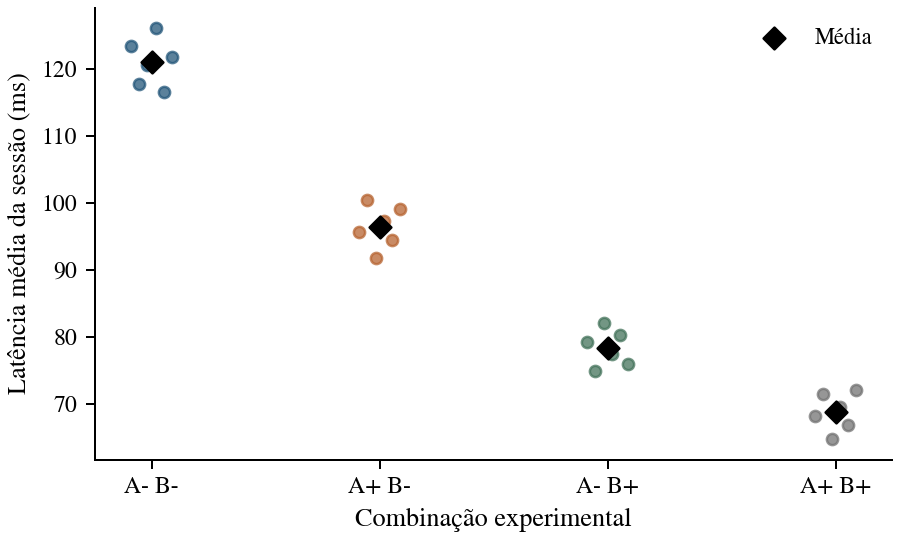

In [8]:
fig, ax = plt.subplots(figsize=(5, 3), layout="constrained")
for i in range(4):
    deslocamento = np.linspace(-0.09, 0.09, replications)
    ax.scatter(i + deslocamento, response[i], color=CORES[i], alpha=0.75)
ax.scatter(np.arange(4), mean_response, marker="D", s=38, color="black", label="Média")
ax.set_xticks(np.arange(4), rotulos)
ax.set_xlabel("Combinação experimental")
ax.set_ylabel("Latência média da sessão (ms)")
ax.legend(frameon=False)
salvar_figura(fig, "01_respostas")


## 5 Modelo na nomenclatura da aula

O modelo completo é

$$y=q_0+q_Ax_A+q_Bx_B+q_{AB}x_Ax_B+\varepsilon.$$

$q_0$ é a média geral. $q_A$, $q_B$ e $q_{AB}$ são os efeitos na notação da aula e também os coeficientes da regressão com sinais $-1$ e $+1$. O termo $q_{AB}$ permite que a mudança associada a um fator dependa do nível do outro.

Na convenção de diferença média entre sinais alto e baixo, o efeito fatorial é $2q$. Manteremos os nomes $q$ e apresentaremos essa diferença em uma coluna separada. A mudança em $A$ quando $B=b$ é $2(q_A+bq_{AB})$. Assim, o efeito principal médio e o efeito em uma condição específica podem responder a perguntas diferentes. [1]


In [9]:
sinais = np.column_stack([np.ones(4), A, B, AB])
q = sinais.T @ mean_response / 4
q0, qA, qB, qAB = q
ajustadas = sinais @ q
y = response.reshape(-1)
X = np.repeat(sinais, replications, axis=0)
modelo = sm.OLS(y, X).fit()
conferencia = pd.DataFrame({"Quantidade": ["q0", "qA", "qB", "qAB"],
                            "Cálculo por sinais": q,
                            "Mínimos quadrados": modelo.params})
np.testing.assert_allclose(q, modelo.params)
salvar_tabela(conferencia, "conferencia_q")


,Quantidade,Cálculo por sinais,Mínimos quadrados
0,q0,91.12,91.12
1,qA,-8.529,-8.529
2,qB,-17.6,-17.6
3,qAB,3.762,3.763


### Por que o cálculo por sinais funciona

As quatro colunas da matriz de sinais são ortogonais. Isso significa que seus produtos internos são zero entre colunas distintas. No desenho balanceado, $X^TX=NI$. Cada coeficiente pode então ser calculado multiplicando as respostas por sua coluna de sinais e dividindo o resultado por $N$.

O ajuste por mínimos quadrados minimiza a soma dos quadrados dos resíduos. Ele fornece as mesmas estimativas porque resolve a mesma projeção das respostas nas colunas do modelo. Se perdermos observações, as simplificações da matriz ortogonal precisam ser revistas.


## 6 Erro experimental e decomposição da variação

No modelo completo, a resposta ajustada de uma combinação é a média de suas replicações. O resíduo mede o afastamento de uma sessão em relação a essa média.

$$e_{ij}=y_{ij}-\bar y_i,\qquad SSE=\sum_i\sum_j e_{ij}^2.$$

$SSY$ soma os quadrados das respostas sem centralização. $SS_0=Nq_0^2$ representa a parcela associada à média geral. $SST=SSY-SS_0$ representa a variação total em torno da média. Cada parcela dos efeitos é calculada por $SS_A=Nq_A^2$, com expressões correspondentes para $B$ e $AB$.

Estimamos quatro parâmetros. Por isso restam $gl_{erro}=N-4=4(r-1)$ graus de liberdade. A estimativa do desvio-padrão dos erros é $s_e=\sqrt{SSE/gl_{erro}}$. O erro-padrão de cada estimativa $q$ é $s_q=s_e/\sqrt{N}$.


In [10]:
residuos_matriz = response - ajustadas[:, None]
residuos = residuos_matriz.reshape(-1)
SSY = np.sum(response ** 2)
SS0 = N * q0 ** 2
SST = SSY - SS0
SSA, SSB, SSAB = N * q[1:] ** 2
SSE = np.sum(residuos ** 2)
gl_erro = N - 4
MSE = SSE / gl_erro
s_e = np.sqrt(MSE)
s_q = s_e / np.sqrt(N)
np.testing.assert_allclose(SST, SSA + SSB + SSAB + SSE)
np.testing.assert_allclose(SSE, modelo.ssr)
resumo_erro = pd.DataFrame({"Quantidade": ["SSE", "gl do erro", "MSE", "s_e", "s_q"],
                           "Valor": [SSE, gl_erro, MSE, s_e, s_q]})
salvar_tabela(resumo_erro, "erro_experimental")


,Quantidade,Valor
0,SSE,189.1
1,gl do erro,20
2,MSE,9.454
3,s_e,3.075
4,s_q,0.6276


## 7 Testes dos efeitos e intervalos de confiança

Para cada efeito $q_j$, o teste bilateral considera

$$H_0\quad q_j=0\qquad H_1\quad q_j\ne0.$$

A estatística $t=\widehat q_j/s_q$ mede a distância até zero em unidades de erro-padrão. Sob as premissas clássicas e $H_0$, usamos a distribuição $t$ com $gl_{erro}$ graus de liberdade. O valor-p é a probabilidade de uma estatística pelo menos tão extrema quanto a observada sob essa hipótese.

O intervalo é $\widehat q_j\pm t_{1-\alpha/2,gl_{erro}}s_q$. Um intervalo que não inclui zero é coerente com a rejeição no teste bilateral correspondente. Um intervalo que inclui zero expressa incerteza suficiente para admitir esse valor e não demonstra que o efeito seja exatamente nulo.

As três hipóteses abaixo são as comparações individuais previamente declaradas neste exemplo. Os intervalos são individuais e não asseguram 90% de cobertura conjunta dos três efeitos. A parte de inferência da coleção desenvolve ajustes para famílias de comparações.


In [11]:
t_critico = stats.t.ppf(1 - ALPHA / 2, gl_erro)
estatisticas_t = q[1:] / s_q
valores_p = 2 * stats.t.sf(np.abs(estatisticas_t), gl_erro)
tabela_efeitos = pd.DataFrame({
    "Efeito": ["qA", "qB", "qAB"],
    "Estimativa em ms": q[1:],
    "Limite inferior": q[1:] - t_critico * s_q,
    "Limite superior": q[1:] + t_critico * s_q,
    "t": estatisticas_t,
    "Valor p": valores_p,
    "Diferença 2q em ms": 2 * q[1:]
})
salvar_tabela(tabela_efeitos, "efeitos_e_intervalos", colunas_p=["Valor p"])


,Efeito,Estimativa em ms,Limite inferior,Limite superior,t,Valor p,Diferença 2q em ms
0,qA,-8.529,-9.612,-7.447,-13.59,1.465e-11,-17.06
1,qB,-17.6,-18.69,-16.52,-28.05,1.563e-17,-35.21
2,qAB,3.762,2.68,4.845,5.995,7.328e-06,7.525


### Efeitos com intervalos individuais

A posição horizontal indica a estimativa de cada $q$. O segmento representa seu IC e a linha vertical indica zero. A figura permite avaliar sinal, magnitude e incerteza. Para interpretar uma mudança operacional, converta o coeficiente para a diferença correspondente e examine a interação.


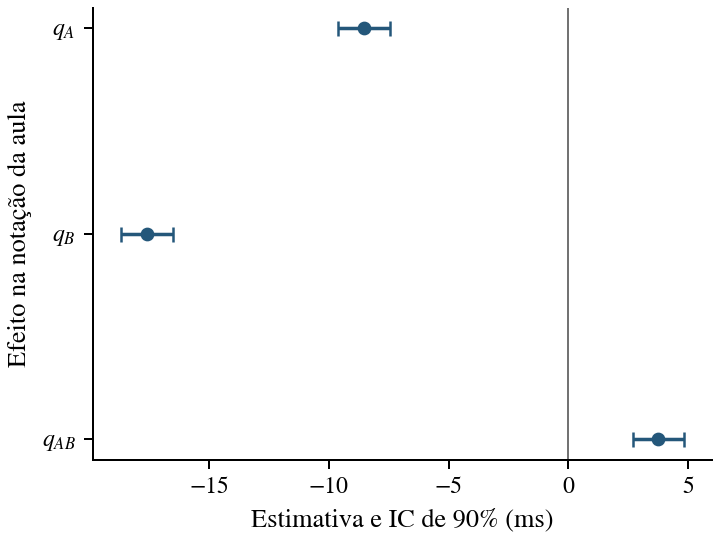

In [12]:
fig, ax = plt.subplots(figsize=(4, 3), layout="constrained")
ax.errorbar(q[1:], np.arange(3), xerr=t_critico * s_q, fmt="o", color=AZUL, capsize=3)
ax.axvline(0, color=CINZA, linewidth=0.8)
ax.set_yticks(np.arange(3), [r"$q_A$", r"$q_B$", r"$q_{AB}$"])
ax.invert_yaxis()
ax.set_xlabel(f"Estimativa e IC de {100 * CONFIDENCE_LEVEL:.0f}% (ms)")
ax.set_ylabel("Efeito na notação da aula")
salvar_figura(fig, "02_efeitos_ic")


## 8 ANOVA e teste global

O teste global pergunta se existe variação sistemática representada pelos três termos explicativos. Suas hipóteses são

$$H_0\quad q_A=q_B=q_{AB}=0,$$
$$H_1\quad \text{pelo menos um desses efeitos é diferente de zero}.$$

A estatística $F=((SSA+SSB+SSAB)/3)/(SSE/gl_{erro})$ compara a variação média associada ao modelo com a variação média do erro. Sob $H_0$, ambas estimam a mesma variância. Um valor grande favorece a presença de algum efeito.

Cada linha de efeito usa um grau de liberdade. Nessas condições, seu $F$ é o quadrado do $t$ para a mesma hipótese. O $F$ global significativo não informa que todos os fatores sejam relevantes e não avalia, por si só, as premissas. [2]


In [13]:
SS_modelo = SSA + SSB + SSAB
F_global = (SS_modelo / 3) / MSE
p_global = stats.f.sf(F_global, 3, gl_erro)
F_termos = np.array([SSA, SSB, SSAB]) / MSE
anova = pd.DataFrame({
    "Fonte": ["A", "B", "AB", "Erro", "Total"],
    "SS": [SSA, SSB, SSAB, SSE, SST],
    "gl": [1, 1, 1, gl_erro, N - 1],
    "MS": [SSA, SSB, SSAB, MSE, np.nan],
    "F": [*F_termos, np.nan, np.nan],
    "Valor p": [*stats.f.sf(F_termos, 1, gl_erro), np.nan, np.nan]
})
np.testing.assert_allclose(F_termos, estatisticas_t ** 2)
np.testing.assert_allclose(F_global, modelo.fvalue)
salvar_tabela(anova, "anova", colunas_p=["Valor p"])
display(Markdown(f"O teste global resultou em F igual a {F_global:.3f}, com 3 e {gl_erro} graus de liberdade e valor-p de {p_global:.3g}."))


,Fonte,SS,gl,MS,F,Valor p
0,A,1746,1,1746,184.7,1.465e-11
1,B,7438,1,7438,786.7,1.563e-17
2,AB,339.8,1,339.8,35.94,7.328e-06
3,Erro,189.1,20,9.454,NaN,
4,Total,9713,23,NaN,NaN,


O teste global resultou em F igual a 335.773, com 3 e 20 graus de liberdade e valor-p de 2.87e-17.

## 9 Interação e efeito simples

O gráfico de interação compara a mudança de $A$ mantendo $B$ fixo. Linhas com inclinações diferentes indicam que uma única diferença média de $A$ não descreve todas as condições.

O efeito simples de $A$ é $2(q_A+bq_{AB})$. Seu erro-padrão vem do contraste $c^T\widehat q$, com $c=(0,2,0,2b)$. A variância estimada é $MSE\,c^T(X^TX)^{-1}c$. Essa expressão considera os coeficientes que participam juntos da mudança.

Se houver teste para um efeito simples, $H_0$ afirma que essa mudança específica é zero e $H_1$ afirma que ela difere de zero. A condição de $B$ precisa fazer parte da interpretação.


,Condição,Mudança em ms,Limite inferior,Limite superior
0,Cache desativado,-24.58,-27.65,-21.52
1,Cache ativado,-9.533,-12.6,-6.472


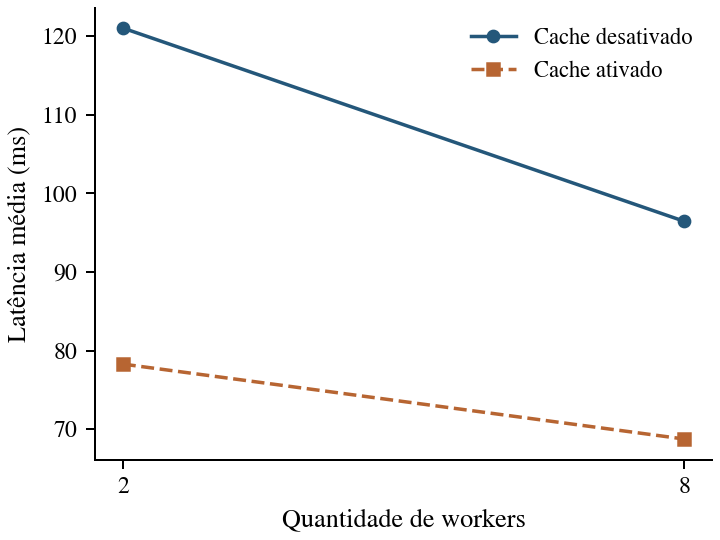

In [14]:
inversa_xtx = np.linalg.inv(X.T @ X)
linhas_simples = []
for b, nome in [(-1, "Cache desativado"), (1, "Cache ativado")]:
    c = np.array([0, 2, 0, 2 * b])
    estimativa = c @ q
    erro_padrao = np.sqrt(MSE * (c @ inversa_xtx @ c))
    linhas_simples.append([nome, estimativa,
                          estimativa - t_critico * erro_padrao,
                          estimativa + t_critico * erro_padrao])
efeitos_simples = pd.DataFrame(linhas_simples,
                              columns=["Condição", "Mudança em ms", "Limite inferior", "Limite superior"])
salvar_tabela(efeitos_simples, "efeitos_simples")

fig, ax = plt.subplots(figsize=(4, 3), layout="constrained")
ax.plot([-1, 1], mean_response[[0, 1]], "o-", color=AZUL, label="Cache desativado")
ax.plot([-1, 1], mean_response[[2, 3]], "s--", color=LARANJA, label="Cache ativado")
ax.set_xticks([-1, 1], ["2", "8"])
ax.set_xlabel("Quantidade de workers")
ax.set_ylabel("Latência média (ms)")
ax.legend(frameon=False)
salvar_figura(fig, "03_interacao")


### Interpretação para a decisão

Uma mudança negativa representa redução da latência. A comparação dos dois efeitos simples mostra se aumentar workers produz o mesmo ganho com e sem cache. A combinação recomendada será escolhida a partir das respostas das combinações e das restrições, sem combinar automaticamente os melhores níveis de gráficos marginais separados.

### Sua vez

Redija duas frases sobre o papel de $A$. A primeira deve descrever o efeito principal médio. A segunda deve explicar a dependência do resultado em relação ao nível de $B$. Use os intervalos para indicar a incerteza e diga qual diferença seria relevante na aplicação.


## 10 Diagnóstico da forma e da variabilidade

No modelo completo, as quatro médias são ajustadas exatamente. Os resíduos mostram erro puro dentro das combinações. Portanto, um gráfico sem estrutura evidente não verifica a forma da resposta entre os níveis ensaiados. Não há graus de liberdade de falta de ajuste contra essas mesmas quatro médias. [3]

O gráfico de resíduos contra valores ajustados ajuda a comparar dispersões. Uma abertura em forma de funil pode sugerir variâncias diferentes. Uma nuvem com poucos pontos exige cautela, porque padrões fracos podem passar despercebidos.

Uma linha horizontal em zero apenas fornece uma referência. A soma dos resíduos igual a zero decorre do ajuste com intercepto e não prova que o modelo esteja correto.


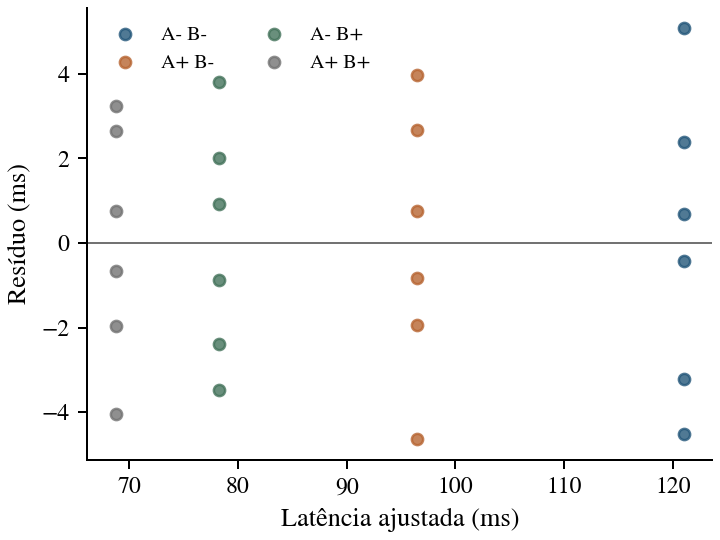

In [15]:
fig, ax = plt.subplots(figsize=(4, 3), layout="constrained")
for i in range(4):
    ax.scatter(np.repeat(ajustadas[i], replications), residuos_matriz[i],
               color=CORES[i], label=rotulos[i], alpha=0.8)
ax.axhline(0, color=CINZA, linewidth=0.8)
ax.set_xlabel("Latência ajustada (ms)")
ax.set_ylabel("Resíduo (ms)")
ax.legend(frameon=False, fontsize=8, ncol=2)
salvar_figura(fig, "04_residuos_ajustados")


### Comparação das dispersões

O teste de Brown-Forsythe compara desvios absolutos em torno da mediana de cada grupo. A mediana reduz a influência de valores extremos sobre a referência de localização. A ideia é verificar se alguns grupos apresentam afastamentos sistematicamente maiores. A implementação usa a variante de Levene centrada na mediana. [4]

$$H_0\quad \text{as quatro condições têm a mesma variância de erro},$$
$$H_1\quad \text{pelo menos uma condição tem variância diferente}.$$

O resultado deve ser lido junto do gráfico e do protocolo. Com poucas replicações por condição, um valor-p alto pode refletir pouca capacidade de detectar uma diferença. A formulação como igualdade de variâncias é especialmente adequada quando as formas das distribuições são comparáveis.

Definimos $z_{ij}=|y_{ij}-\widetilde y_i|$, em que $\widetilde y_i$ é a mediana da combinação $i$. Com $g=4$ grupos, $\bar z_i$ como média dos desvios do grupo e $\bar z$ como média geral, calculamos

$$W=\frac{\sum_i r(\bar z_i-\bar z)^2/(g-1)}{\sum_i\sum_j(z_{ij}-\bar z_i)^2/(N-g)}.$$

O numerador mede diferenças de dispersão entre condições. O denominador mede quanto os desvios variam dentro das condições. Valores grandes de $W$ favorecem a alternativa. A referência $F_{g-1,N-g}$ é aproximada e será usada para obter o valor-p. Vamos construir a conta antes de compará-la com a biblioteca.


In [16]:
z = np.abs(response - np.median(response, axis=1, keepdims=True))
media_z = z.mean(axis=1)
g = response.shape[0]
ss_entre_z = replications * np.sum((media_z - z.mean()) ** 2)
ss_dentro_z = np.sum((z - media_z[:, None]) ** 2)
W_manual = (ss_entre_z / (g - 1)) / (ss_dentro_z / (N - g))
p_bf_manual = stats.f.sf(W_manual, g - 1, N - g)
bf = stats.levene(*response, center="median")
np.testing.assert_allclose([W_manual, p_bf_manual], [bf.statistic, bf.pvalue])
resultado_bf = pd.DataFrame({"Procedimento": ["Brown-Forsythe"],
                            "Estatística": [W_manual], "gl numerador": [g - 1],
                            "gl denominador": [N - g], "Valor p": [p_bf_manual]})
salvar_tabela(resultado_bf, "brown_forsythe", colunas_p=["Valor p"])


,Procedimento,Estatística,gl numerador,gl denominador,Valor p
0,Brown-Forsythe,0.1319,3,20,0.9399


## 11 Normalidade dos erros

No gráfico Q-Q, comparamos os resíduos ordenados com quantis de uma distribuição normal. Se o modelo normal é uma aproximação adequada, os pontos tendem a acompanhar uma reta. Curvaturas persistentes, assimetria e caudas muito afastadas merecem investigação.

A normalidade relevante é a dos erros condicionados aos fatores. As respostas reunidas podem formar grupos com médias diferentes e não precisam apresentar um histograma normal. O Q-Q é um diagnóstico gráfico e não possui, sozinho, uma hipótese formal acompanhada de valor-p. A reta ajustada no gráfico é uma referência visual e nenhum teste dessa regressão auxiliar será usado para avaliar normalidade.

Os resíduos são estimados após o ajuste. Mesmo sob erros independentes, sua covariância é $\sigma^2(I-H)$. Essa dependência estrutural deve ser considerada ao calibrar testes e envelopes. A parte de resíduos da coleção mostra a construção de um envelope por simulação e a interpretação cautelosa dos testes de normalidade.


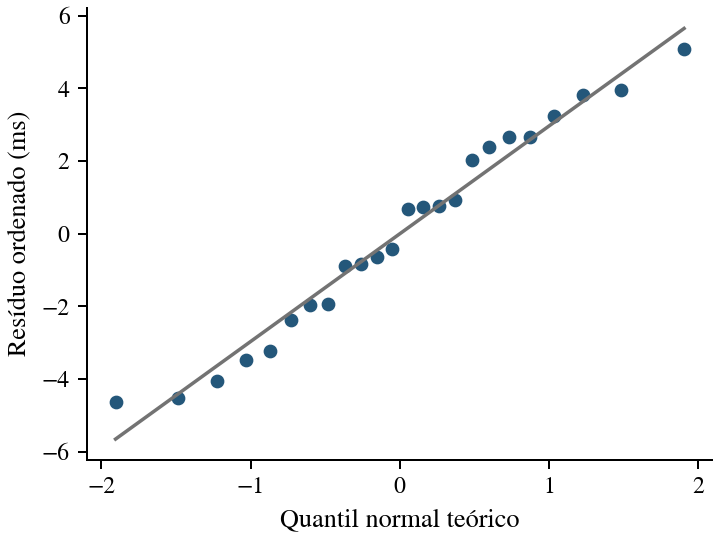

In [17]:
quantis, residuos_ordenados = stats.probplot(residuos, dist="norm", fit=False)
reta = stats.linregress(quantis, residuos_ordenados)
fig, ax = plt.subplots(figsize=(4, 3), layout="constrained")
ax.scatter(quantis, residuos_ordenados, color=AZUL)
ax.plot(quantis, reta.intercept + reta.slope * np.asarray(quantis), color=CINZA)
ax.set_xlabel("Quantil normal teórico")
ax.set_ylabel("Resíduo ordenado (ms)")
salvar_figura(fig, "05_qq_residuos")


## 12 Independência e sequência de execução

Independência é uma propriedade dos erros e do processo de coleta. O gráfico sequencial procura deriva, ciclos e agrupamentos em sessões próximas. Essas estruturas podem indicar aquecimento, mudança de carga ou outras condições não registradas.

Para construir esse gráfico, associamos cada resíduo à sua sessão e ordenamos pela sequência realmente executada. Ordenar pelas combinações destruiria a interpretação temporal. Um gráfico sem padrão aparente fornece evidência limitada e não substitui a descrição do protocolo de replicação.


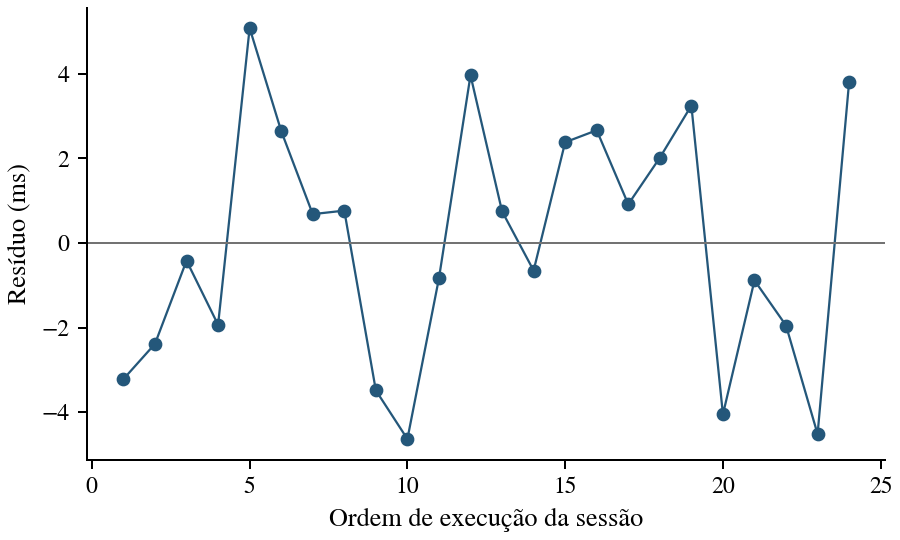

In [18]:
diagnostico = dados.copy()
diagnostico["residuo_ms"] = residuos
diagnostico = diagnostico.sort_values("ordem_execucao")
fig, ax = plt.subplots(figsize=(5, 3), layout="constrained")
ax.plot(diagnostico["ordem_execucao"], diagnostico["residuo_ms"],
        "o-", color=AZUL, linewidth=0.9)
ax.axhline(0, color=CINZA, linewidth=0.8)
ax.set_xlabel("Ordem de execução da sessão")
ax.set_ylabel("Resíduo (ms)")
salvar_figura(fig, "06_residuos_ordem")


## 13 Observações discrepantes e influência

Um resíduo externamente studentizado divide $e_i$ por $s_{e(i)}\sqrt{1-h_{ii}}$. A escala $s_{e(i)}$ é estimada sem a observação examinada. Isso reduz o efeito de uma resposta extrema inflar sua própria referência de variabilidade. Sob o modelo normal, esse resíduo tem distribuição $t$ com $N-5$ graus de liberdade, desde que a exclusão preserve o posto do modelo.

O teste individual considera $H_0$ de que a observação segue a mesma média e a mesma estrutura de erros do modelo. A alternativa é um deslocamento na média daquela observação. Ao examinar todas as sessões, usaremos um limite de Bonferroni para controlar a probabilidade de ao menos uma sinalização falsa nessa família.

A alavancagem $h_{ii}$ depende da matriz dos fatores. Neste fatorial completo balanceado, ela é $1/r$ em todas as sessões. A distância de Cook resume quanto os valores ajustados mudariam ao retirar uma observação, combinando discrepância e alavancagem. Ela é um indicador de influência, sem um par próprio de hipóteses $H_0$ e $H_1$. Um limite de triagem não é uma autorização para excluir. [5]

Com $p=4$ parâmetros, a distância de Cook pode ser calculada diretamente a partir do ajuste completo

$$D_i=\frac{e_i^2}{p s_e^2}\frac{h_{ii}}{(1-h_{ii})^2}.$$

Um resíduo grande pesa mais quando a posição experimental também tem alta alavancagem. Como todas as alavancagens são iguais neste projeto, a ordenação de Cook acompanha a magnitude dos resíduos. O valor $4/N$ será mostrado como referência de triagem e não como ponto crítico de um teste.

Para os resíduos externos $t_i$, o limite bilateral de Bonferroni é

$$c=t_{1-\alpha/(2N),N-p-1}.$$

Investigamos $|t_i|>c$. A divisão por $N$ distribui o nível de significância entre os $N$ exames, e a divisão por dois considera as duas caudas. A desigualdade de Bonferroni controla a chance de ao menos uma sinalização falsa mesmo sem independência entre esses exames, desde que as referências individuais sejam válidas.


In [19]:
influencia = modelo.get_influence()
studentizados = influencia.resid_studentized_external
alavancagem = influencia.hat_matrix_diag
cook = influencia.cooks_distance[0]
K = X.shape[1]
cook_manual = residuos**2 * alavancagem / (K * s_e**2 * (1 - alavancagem)**2)
np.testing.assert_allclose(cook_manual, cook)
limite_bonferroni = stats.t.ppf(1 - ALPHA / (2 * N), gl_erro - 1)
tabela_influencia = pd.DataFrame({
    "Sessão": dados["sessao"],
    "Resíduo externo": studentizados,
    "Alavancagem": alavancagem,
    "Cook": cook,
    "Investigar resíduo": np.abs(studentizados) > limite_bonferroni,
    "Triagem de Cook": cook > 4 / N
})
np.testing.assert_allclose(alavancagem, 1 / replications)
salvar_tabela(tabela_influencia.sort_values("Cook", ascending=False).head(6), "observacoes_para_revisao")


,Sessão,Resíduo externo,Alavancagem,Cook,Investigar resíduo,Triagem de Cook
3,4,1.931,0.1667,0.164,False,False
8,9,-1.731,0.1667,0.1362,False,False
4,5,-1.681,0.1667,0.1295,False,False
20,21,-1.486,0.1667,0.1041,False,False
7,8,1.452,0.1667,0.09986,False,False
14,15,1.391,0.1667,0.09245,False,False


### Análise de sensibilidade

Uma análise de sensibilidade compara a conclusão em cenários de análise justificados. Retirar provisoriamente a observação mais influente permite medir o quanto a estimativa depende dela. Isso não declara a observação inválida e não altera o conjunto principal de resultados.

A retirada deixa uma combinação com uma replicação a menos. Por isso o cenário alternativo será ajustado com a matriz das observações restantes. Não reutilizaremos as fórmulas simplificadas do balanceamento como se nada tivesse mudado.


In [20]:
i_sensivel = int(np.argmax(cook))
sessao_sensivel = dados.iloc[i_sensivel]["sessao"]
manter = np.arange(N) != i_sensivel
modelo_sensibilidade = sm.OLS(y[manter], X[manter]).fit()
sensibilidade = pd.DataFrame({"Quantidade": ["q0", "qA", "qB", "qAB"],
                              "Todas as sessões": modelo.params,
                              "Sem a sessão em estudo": modelo_sensibilidade.params,
                              "Mudança": modelo_sensibilidade.params - modelo.params})
salvar_tabela(sensibilidade, "sensibilidade")
display(Markdown(f"A sessão {sessao_sensivel} foi retirada apenas no cenário de sensibilidade. O resultado principal continua usando todas as sessões."))


,Quantidade,Todas as sessões,Sem a sessão em estudo,Mudança
0,q0,91.12,90.87,-0.2542
1,qA,-8.529,-8.275,0.2542
2,qB,-17.6,-17.35,0.2542
3,qAB,3.763,3.508,-0.2542


A sessão 4 foi retirada apenas no cenário de sensibilidade. O resultado principal continua usando todas as sessões.

## 14 Parecer sobre os diagnósticos

Antes de prosseguir, registre o que foi observado. O exemplo contém poucas sessões por condição e quatro valores ajustados distintos. Portanto, a ausência de um padrão evidente não é uma demonstração das premissas.

| Aspecto | Evidência a registrar | Consequência a discutir |
| --- | --- | --- |
| Forma funcional | Modelo completo nas médias dos vértices | Não verificar curvatura entre níveis |
| Variância | Dispersão por grupo e Brown-Forsythe | Avaliar se a inferência comum é plausível |
| Normalidade | Forma do Q-Q e observações extremas | Qualificar a inferência clássica |
| Independência | Protocolo e sequência das sessões | Verificar possível dependência adicional |
| Influência | Resíduos externos e sensibilidade | Identificar resultados que dependem de poucas sessões |

Se houver uma falha importante de desenho, a próxima etapa pode ser nova coleta. Se houver uma falha de forma ou de variância, a análise pode exigir outro modelo. O notebook de falhas experimentais mostra esses caminhos.


## 15 IC da média e intervalos de predição

Vamos quantificar a incerteza de uma configuração escolhida. O vetor $x_0=(1,a,b,ab)$ representa seus níveis. A quantidade $h_0=x_0^T(X^TX)^{-1}x_0$ mede a variância relativa da média ajustada. Em um vértice deste fatorial, $h_0=1/r$.

O IC da média é

$$\widehat y_0\pm t_{1-\alpha/2,gl_{erro}}s_e\sqrt{h_0}.$$

Para uma nova sessão, somamos a variabilidade própria dessa sessão à incerteza da média ajustada

$$\widehat y_0\pm t_{1-\alpha/2,gl_{erro}}s_e\sqrt{1+h_0}.$$

Para a média de $m$ novas sessões independentes, a variabilidade futura é dividida por $m$

$$\widehat y_0\pm t_{1-\alpha/2,gl_{erro}}s_e\sqrt{1/m+h_0}.$$

O intervalo de predição individual é mais largo porque inclui duas fontes de incerteza. Esses cálculos usam o modelo normal com variância comum e estabilidade do processo. Um ajuste de erro-padrão robusto para coeficientes não fornece automaticamente os mesmos intervalos preditivos.


In [21]:
melhor = int(np.argmin(mean_response))
x0 = sinais[melhor]
y0 = float(x0 @ q)
h0 = float(x0 @ inversa_xtx @ x0)
m_novo = 6
larguras = t_critico * s_e * np.sqrt([h0, 1 + h0, 1 / m_novo + h0])
intervalos = pd.DataFrame({
    "Alvo": ["Média populacional", "Nova sessão", f"Média de {m_novo} novas sessões"],
    "Estimativa em ms": y0,
    "Limite inferior": y0 - larguras,
    "Limite superior": y0 + larguras
})
previsao_biblioteca = modelo.get_prediction(x0.reshape(1, -1)).summary_frame(alpha=ALPHA)
np.testing.assert_allclose(intervalos.iloc[0][["Limite inferior", "Limite superior"]].to_numpy(dtype=float),
                           previsao_biblioteca[["mean_ci_lower", "mean_ci_upper"]].to_numpy().ravel())
np.testing.assert_allclose(intervalos.iloc[1][["Limite inferior", "Limite superior"]].to_numpy(dtype=float),
                           previsao_biblioteca[["obs_ci_lower", "obs_ci_upper"]].to_numpy().ravel())
salvar_tabela(intervalos, "intervalos_media_e_predicao")
display(Markdown(f"A menor média observada está na combinação {rotulos[melhor]}, com estimativa de {y0:.2f} ms e h0 igual a {h0:.4f}."))


,Alvo,Estimativa em ms,Limite inferior,Limite superior
0,Média populacional,68.75,66.59,70.91
1,Nova sessão,68.75,63.02,74.48
2,Média de 6 novas sessões,68.75,65.69,71.81


A menor média observada está na combinação A+ B+, com estimativa de 68.75 ms e h0 igual a 0.1667.

### Comparação visual dos três intervalos

Os segmentos se referem à mesma configuração, mas a objetos diferentes. Um IC de média estreito não deve ser apresentado como a faixa esperada para uma execução individual. Os intervalos abaixo são pontuais para a configuração considerada. A escolha da melhor configuração com os mesmos dados acrescenta uma questão de seleção, que motiva a confirmação independente.


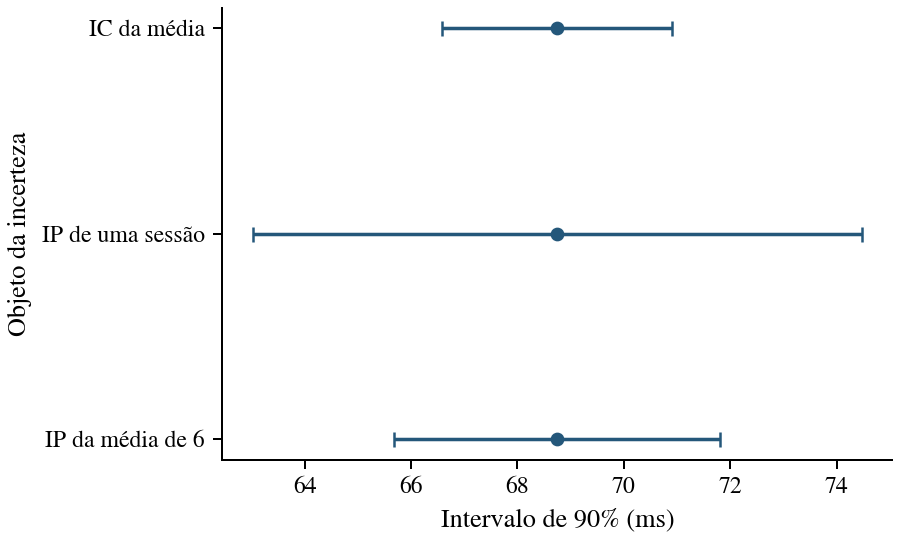

In [22]:
fig, ax = plt.subplots(figsize=(5, 3), layout="constrained")
ax.errorbar([y0] * 3, np.arange(3), xerr=larguras, fmt="o", color=AZUL, capsize=3)
ax.set_yticks(np.arange(3), ["IC da média", "IP de uma sessão", "IP da média de 6"])
ax.invert_yaxis()
ax.set_xlabel(f"Intervalo de {100 * CONFIDENCE_LEVEL:.0f}% (ms)")
ax.set_ylabel("Objeto da incerteza")
salvar_figura(fig, "07_intervalos")


## 16 Confirmação com novas sessões

Depois da seleção, executamos seis novas sessões em $A+B+$ e seis na configuração inicial $A-B-$. Os valores abaixo também são sintéticos. A confirmação não foi usada para escolher a configuração.

No projeto real, registre os níveis realizados e o protocolo das novas sessões. A interpretação da confirmação exige que a configuração avaliada corresponda à recomendação e que as novas execuções sejam independentes das utilizadas no ajuste.

Ao usar um CSV próprio, substitua também os dois arrays de confirmação por novas medições do seu projeto e registre os níveis realmente executados. Depois dessa substituição, altere `CONFIRMACAO_DO_EXEMPLO` para `False`. A verificação abaixo impede que os dados sintéticos desta aula sejam usados por engano para confirmar um experimento diferente. Não altere apenas os níveis no código para fazê-los coincidir com a recomendação.

A primeira comparação verifica a média das novas sessões em relação ao intervalo de predição de uma média futura. Um valor dentro do intervalo indica compatibilidade com a previsão sob o modelo. Isso não prova ausência de mudanças no processo.


In [23]:
CONFIRMACAO_DO_EXEMPLO = True
confirmacao = np.array([67.1, 70.3, 66.8, 72.0, 68.6, 69.4], dtype=float)
referencia_nova = np.array([120.5, 124.1, 119.8, 122.6, 118.9, 121.7], dtype=float)
A_CONFIRMADO, B_CONFIRMADO = 1, 1
x_confirmacao = np.array([1, A_CONFIRMADO, B_CONFIRMADO, A_CONFIRMADO * B_CONFIRMADO])
if ARQUIVO_CSV != ARQUIVO_EXEMPLO and CONFIRMACAO_DO_EXEMPLO:
    raise ValueError("Substitua os dados de confirmação pelos dados do seu projeto")
if A_CONFIRMADO not in [-1, 1] or B_CONFIRMADO not in [-1, 1]:
    raise ValueError("Registre os níveis codificados realmente usados na confirmação")
for serie in [confirmacao, referencia_nova]:
    if serie.ndim != 1 or serie.size < 2 or not np.isfinite(serie).all():
        raise ValueError("A confirmação precisa de ao menos duas respostas finitas por condição")
coincide = bool(np.array_equal(x0, x_confirmacao))
if not coincide:
    raise ValueError("As medições de confirmação não correspondem à configuração selecionada")
rotulo_confirmacao = rotulos[melhor]
media_prevista_confirmacao = float(x_confirmacao @ q)
h_confirmacao = float(x_confirmacao @ inversa_xtx @ x_confirmacao)
media_confirmacao = confirmacao.mean()
meia_largura_confirmacao = t_critico * s_e * np.sqrt(h_confirmacao + 1 / confirmacao.size)
ip_confirmacao = np.array([media_prevista_confirmacao - meia_largura_confirmacao,
                           media_prevista_confirmacao + meia_largura_confirmacao])
resultado_confirmacao = pd.DataFrame({
    "Quantidade": ["Média prevista", "Média das novas sessões", "Limite inferior do IP", "Limite superior do IP"],
    "Latência em ms": [media_prevista_confirmacao, media_confirmacao, *ip_confirmacao]
})
salvar_tabela(resultado_confirmacao, "confirmacao")
display(Markdown(f"As novas sessões correspondem à configuração {rotulo_confirmacao}, selecionada no fatorial."))


,Quantidade,Latência em ms
0,Média prevista,68.75
1,Média das novas sessões,69.03
2,Limite inferior do IP,65.69
3,Limite superior do IP,71.81


As novas sessões correspondem à configuração A+ B+, selecionada no fatorial.

### IC próprio da etapa de confirmação

Também podemos estimar a média usando somente as novas sessões. Para essa amostra independente, o IC é $\bar y\pm t_{1-\alpha/2,m-1}s/\sqrt m$. O desvio-padrão $s$ agora é calculado a partir da confirmação, e os graus de liberdade são $m-1$.

Esse intervalo tem uma base de dados diferente do IC produzido pelo modelo fatorial. Apresentar ambos ajuda a separar a previsão original da evidência obtida depois da escolha.

O IC t é exato para observações independentes com distribuição normal. Com apenas seis sessões, a normalidade aproximada e a estabilidade do protocolo precisam de atenção. O tamanho pequeno da amostra não permite dispensar essa avaliação.


In [24]:
m = confirmacao.size
s_confirmacao = confirmacao.std(ddof=1)
t_confirmacao = stats.t.ppf(1 - ALPHA / 2, m - 1)
ic_confirmacao = media_confirmacao + np.array([-1, 1]) * t_confirmacao * s_confirmacao / np.sqrt(m)
tabela_ic_confirmacao = pd.DataFrame({"Média em ms": [media_confirmacao],
                                      "Limite inferior": [ic_confirmacao[0]],
                                      "Limite superior": [ic_confirmacao[1]],
                                      "gl": [m - 1]})
salvar_tabela(tabela_ic_confirmacao, "ic_independente_confirmacao")


,Média em ms,Limite inferior,Limite superior,gl
0,69.03,67.41,70.66,5


### Ganho em relação à configuração inicial

As duas séries de confirmação são independentes neste exemplo. Usaremos um IC de Welch para a diferença entre as médias, sem impor igualdade de variâncias entre as duas condições. O erro-padrão combina $s_1^2/m_1+s_2^2/m_2$. Os graus de liberdade de Welch aproximam a incerteza dessas duas estimativas de variância. [6]

Se $G=\bar y_1-\bar y_2$ é o ganho estimado, calculamos

$$EP(G)=\sqrt{\frac{s_1^2}{m_1}+\frac{s_2^2}{m_2}},$$

$$\nu=\frac{(s_1^2/m_1+s_2^2/m_2)^2}{(s_1^2/m_1)^2/(m_1-1)+(s_2^2/m_2)^2/(m_2-1)},$$

$$IC(G)=G\pm t_{1-\alpha/2,\nu}EP(G).$$

Os tamanhos $m_1$ e $m_2$ pertencem às novas sessões da referência e da configuração escolhida. As variâncias $s_1^2$ e $s_2^2$ são calculadas separadamente. A expressão de $\nu$ reduz os graus de liberdade quando a incerteza fica concentrada em uma das amostras. Não arredondamos $\nu$ para calcular o quantil t.

Definimos o ganho como média da configuração inicial menos média da configuração escolhida. Ganhos positivos indicam redução de latência. Se um teste bilateral fosse a pergunta, teríamos $H_0$ de ganho igual a zero e $H_1$ de ganho diferente de zero. O interesse prático aqui é comparar o IC do ganho com os 5 ms definidos no planejamento.

Esse procedimento seria inadequado se as duas listas fossem medições pareadas da mesma sessão sem que a dependência fosse considerada. A escolha entre análise pareada e independente vem do desenho.

A aproximação de Welch permite variâncias diferentes, mas não elimina a necessidade de uma distribuição aproximadamente normal com amostras tão pequenas. Observações extremas, dependência e mudanças de protocolo também devem ser examinadas nesta etapa.


In [25]:
m1, m2 = referencia_nova.size, confirmacao.size
v1, v2 = referencia_nova.var(ddof=1), confirmacao.var(ddof=1)
ganho = referencia_nova.mean() - confirmacao.mean()
se_ganho = np.sqrt(v1 / m1 + v2 / m2)
gl_welch = (v1 / m1 + v2 / m2) ** 2 / ((v1 / m1) ** 2 / (m1 - 1) + (v2 / m2) ** 2 / (m2 - 1))
t_welch = stats.t.ppf(1 - ALPHA / 2, gl_welch)
ic_ganho = ganho + np.array([-1, 1]) * t_welch * se_ganho
welch_biblioteca = stats.ttest_ind(referencia_nova, confirmacao, equal_var=False)
ic_welch_biblioteca = welch_biblioteca.confidence_interval(confidence_level=CONFIDENCE_LEVEL)
np.testing.assert_allclose(gl_welch, welch_biblioteca.df)
np.testing.assert_allclose(ic_ganho, [ic_welch_biblioteca.low, ic_welch_biblioteca.high])
ganho_tabela = pd.DataFrame({"Ganho em ms": [ganho], "Erro-padrão": [se_ganho],
                             "gl de Welch": [gl_welch],
                             "Limite inferior": [ic_ganho[0]], "Limite superior": [ic_ganho[1]]})
salvar_tabela(ganho_tabela, "ganho_confirmado")


,Ganho em ms,Erro-padrão,gl de Welch,Limite inferior,Limite superior
0,52.23,1.122,9.991,50.2,54.27


## 17 Conclusão a partir das evidências

Uma conclusão precisa separar resultado estatístico, importância prática e alcance. O texto a seguir usa os valores calculados, enquanto a avaliação das premissas continua exigindo a leitura dos diagnósticos e do protocolo.

O limite de uma nova sessão será avaliado pelo intervalo preditivo individual do modelo. Esse intervalo não é um intervalo de tolerância e não assegura que uma proporção fixada de todas as sessões futuras cumpra o limite. Se esse for o objetivo operacional, será necessário formular uma análise própria para essa proporção.


In [26]:
limite_ip_sessao = media_prevista_confirmacao + t_critico * s_e * np.sqrt(1 + h_confirmacao)
texto_media = "ficou abaixo" if ic_confirmacao[1] < LIMITE_MEDIA else "não ficou abaixo"
texto_ganho = "superou" if ic_ganho[0] > GANHO_RELEVANTE else "não superou"
texto_sessao = "ficou abaixo" if limite_ip_sessao < LIMITE_SESSAO else "não ficou abaixo"
display(Markdown(
    f"Nas novas sessões de {rotulo_confirmacao}, a latência média foi {media_confirmacao:.2f} ms, "
    f"com IC de {100 * CONFIDENCE_LEVEL:.0f}% entre {ic_confirmacao[0]:.2f} e {ic_confirmacao[1]:.2f} ms. "
    f"O limite superior desse IC {texto_media} de {LIMITE_MEDIA:.0f} ms. "
    f"O ganho estimado em relação à configuração inicial foi {ganho:.2f} ms, "
    f"com IC entre {ic_ganho[0]:.2f} e {ic_ganho[1]:.2f} ms. "
    f"O limite inferior do ganho {texto_ganho} os {GANHO_RELEVANTE:.0f} ms definidos como relevantes. "
    f"O limite superior do IP de uma sessão, calculado pelo modelo fatorial, {texto_sessao} de {LIMITE_SESSAO:.0f} ms."
))


Nas novas sessões de A+ B+, a latência média foi 69.03 ms, com IC de 90% entre 67.41 e 70.66 ms. O limite superior desse IC ficou abaixo de 75 ms. O ganho estimado em relação à configuração inicial foi 52.23 ms, com IC entre 50.20 e 54.27 ms. O limite inferior do ganho superou os 5 ms definidos como relevantes. O limite superior do IP de uma sessão, calculado pelo modelo fatorial, ficou abaixo de 80 ms.

### Condições que devem acompanhar a recomendação

A recomendação se refere aos níveis ensaiados, ao perfil de carga, à versão do serviço e ao protocolo de medição. Os dados são sintéticos. Uma aplicação real deve verificar se a reinicialização, o aquecimento e o isolamento das sessões sustentam a interpretação de replicações independentes.

O fatorial compara quatro configurações. Ele não demonstra que não exista uma alternativa melhor em outro número de workers ou em outra política de cache. A escolha de novos níveis pode motivar um próximo experimento.


## 18 Estrutura sugerida para o relatório

### Problema e objetivo

Apresente a decisão, a resposta, a unidade de medida e o ganho mínimo relevante. Explique a importância desses critérios para o sistema estudado.

### Planejamento e execução

Descreva fatores, níveis, replicações e unidade experimental. Registre aleatorização, condições de controle, desvios de execução e critérios de tratamento de falhas.

### Análise

Apresente a matriz do experimento, as respostas individuais, os efeitos $q$, os ICs e a ANOVA. Explique as hipóteses testadas e interprete a interação no contexto do sistema.

### Validação

Discuta forma funcional, variância, independência, normalidade e influência. Relacione os gráficos ao protocolo. Diga quais limitações impedem uma conclusão mais forte.

### Confirmação e conclusão

Apresente as novas sessões, a compatibilidade com a previsão e o ganho obtido. Diferencie média e execução individual. Conclua com uma recomendação delimitada pelas condições do estudo.


## 19 Verificação final do projeto

| Pergunta | Evidência esperada |
| --- | --- |
| Há quatro combinações com níveis identificados | Matriz e dicionário de fatores |
| As replicações correspondem à unidade experimental | Protocolo de coleta |
| A ordem real foi preservada | Registro de execução |
| Os valores originais estão disponíveis | Array e CSV |
| As contas podem ser reproduzidas | Células executadas em sequência |
| Os efeitos usam a nomenclatura da aula | Tabelas de $q$ e explicação da codificação |
| As hipóteses estão relacionadas às perguntas | Texto antes dos testes |
| Cada figura tem eixos, unidades e interpretação | Figura acompanhada de texto |
| As premissas foram examinadas | Diagnósticos e discussão |
| A recomendação foi confirmada | Novas execuções e comparação adequada |

Uma resposta negativa nessa tabela aponta o que precisa ser documentado ou revisto. Não transforme a tabela em uma regra de aprovação automática baseada apenas em valores-p.


## 20 Exercício final

1. Escolha uma alteração do protocolo que possa comprometer a independência das sessões e explique como detectá-la ou preveni-la.
2. Explique por que o efeito médio de workers não é suficiente para descrever a interação com cache.
3. Compare o IC da média, o IP de uma sessão e o IP de seis novas sessões. Diga qual deles usar para cada pergunta operacional.
4. Mostre como sua recomendação mudaria se o menor ganho relevante fosse 60 ms.
5. Escreva uma conclusão que mantenha a diferença entre compatibilidade com o modelo e demonstração das premissas.

### Respostas comentadas

Manter o estado de cache de uma sessão para outra pode ligar as respostas e mudar o que uma replicação representa. O protocolo precisa definir reinicialização, aquecimento e carga. A interação significa que o efeito de workers depende do nível do cache, o que aparece nos efeitos simples e nas inclinações das linhas.

O IC da média quantifica a incerteza da média populacional. O IP de uma sessão inclui a variabilidade de uma nova observação. O IP de seis sessões inclui a variabilidade da média desse novo conjunto. Um critério de 60 ms exige comparar o IC do ganho com esse novo patamar e pode não sustentar uma recomendação de ganho mínimo, mesmo que a diferença em relação a zero seja clara.

Uma conclusão adequada descreve o padrão observado e a incerteza, limita a recomendação ao protocolo e reconhece o que os diagnósticos não conseguem verificar. Ela não afirma que um valor-p alto provou a independência ou a normalidade.


## Referências

1. Aula 5.1 da disciplina Projeto e Análise de Experimentos. Projetos fatoriais com replicações. Jain, R. The Art of Computer Systems Performance Analysis. Wiley, 1991. Complemento de notação em [NIST sobre efeitos e coeficientes](https://www.itl.nist.gov/div898/handbook/pri/section5/pri594.htm).
2. [Documentação de testes F de hipóteses lineares no statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.f_test.html).
3. [NIST sobre erro puro e falta de ajuste](https://www.itl.nist.gov/div898/handbook/pmd/section4/pmd446.htm).
4. [Documentação do teste de Levene e da versão centrada na mediana](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.levene.html).
5. [Documentação de resíduos e medidas de influência em OLS](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.OLSInfluence.html).
6. Aula 4 da disciplina Projeto e Análise de Experimentos. Comparação entre experimentos. Complemento em [SciPy sobre comparação de duas amostras independentes](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html).

Montgomery, D. C. Design and Analysis of Experiments. Referência complementar para planejamento, interações, ANOVA e análise de resíduos, conforme a edição adotada na disciplina.
